In [1]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
from QGP.Soliton_Gen import *
from Utilities import *
from Eigenvalues import *

import config
i = 1j

# One epsilon
path_uns_one = "../../../Heaven_scripts/Results/DS_unstable/eps/one_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"
path_st_one = "../../../Heaven_scripts/Results/DS_stable/eps/one_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"


folder_control_st_one = path_st_one + "st_k_-50_control_N_1000000_Nt_100000_L_10000/"
folder_control_uns_one = path_uns_one + "uns_k_-50_control_N_1000000_Nt_100000_L_10000/"

#folder_gauss_rand_st_one = path_st_one + "st_k_-50_rand_N_1000000_Nt_100000_L_10000/"
#folder_gauss_rand_uns_one = path_uns_one + "uns_k_-50_rand_N_1000000_Nt_100000_L_10000/"

folder_ev_st_one = path_st_one + "st_k_-50_ev_N_1000000_Nt_100000_L_10000/"
folder_ev_uns_one = path_uns_one + "uns_k_-50_ev_N_1000000_Nt_100000_L_10000/"

folder_gauss_st_one = path_st_one + "st_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/st_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"
folder_gauss_uns_one =  path_uns_one + "uns_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/uns_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"

# Two epsilon
path_uns_two = "../../../Heaven_scripts/Results/DS_unstable/eps/two_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"
path_st_two = "../../../Heaven_scripts/Results/DS_stable/eps/two_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"

folder_control_st_two = path_st_two + "st_k_-50_control_N_1000000_Nt_100000_L_10000/"
folder_control_uns_two = path_uns_two + "uns_k_-50_control_N_1000000_Nt_100000_L_10000/"

#folder_gauss_rand_st_two = path_st_two + "st_k_-50_rand_N_1000000_Nt_100000_L_10000/"
#folder_gauss_rand_uns_two = path_uns_two + "uns_k_-50_rand_N_1000000_Nt_100000_L_10000/"

folder_ev_st_two = path_st_two + "st_k_-50_ev_N_1000000_Nt_100000_L_10000/"
folder_ev_uns_two = path_uns_two + "uns_k_-50_ev_N_1000000_Nt_100000_L_10000/"

folder_gauss_st_two = path_st_two + "st_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/st_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"
folder_gauss_uns_two =  path_uns_two + "uns_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/uns_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"


# Three epsilon
path_uns_three = "../../../Heaven_scripts/Results/DS_unstable/eps/three_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"
path_st_three = "../../../Heaven_scripts/Results/DS_stable/eps/three_eps/" #"../../../Heaven_scripts/Results/DS_unstable/A_random/"

folder_control_st_three = path_st_three + "st_k_-50_control_N_1000000_Nt_100000_L_10000/"
folder_control_uns_three = path_uns_three + "uns_k_-50_control_N_1000000_Nt_100000_L_10000/"

#folder_gauss_rand_st_three = path_st_three + "st_k_-50_rand_N_1000000_Nt_100000_L_10000/"
#folder_gauss_rand_uns_three = path_uns_three + "uns_k_-50_rand_N_1000000_Nt_100000_L_10000/"

folder_ev_st_three = path_st_three + "st_k_-50_ev_N_1000000_Nt_100000_L_10000/"
folder_ev_uns_three = path_uns_three + "uns_k_-50_ev_N_1000000_Nt_100000_L_10000/"

folder_gauss_st_three = path_st_three + "st_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/st_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"
folder_gauss_uns_three =  path_uns_three + "uns_k_-50_cons_N_1000000_Nt_100000_L_10000/" #"../../../Heaven_scripts/DS_unstable/A_random/uns_k_-50_gauss_cons_N_1000000_Nt_100000_L_10000/"


In [2]:
def load_files(PATH, w_final_index):
    files = {}
    
    error_L2_file = gzip.GzipFile(PATH+"error_L2.npy.gz", "r")
    error_H1_file = gzip.GzipFile(PATH+"error_H1.npy.gz", "r")
    error_inf_file = gzip.GzipFile(PATH+"error_inf.npy.gz", "r")
    error_grad_inf_file = gzip.GzipFile(PATH+"error_grad_inf.npy.gz", "r")
    
    t_file = gzip.GzipFile(PATH+"time.npy.gz", "r")
    x_file = gzip.GzipFile(PATH+"space.npy.gz", "r")
    final_sol = gzip.GzipFile(PATH+"w_"+f"{w_final_index:010d}"+".npy.gz", "r")
    energy_file = gzip.GzipFile(PATH+"energy.npy.gz", "r")
    mass_file = gzip.GzipFile(PATH+"mass.npy.gz", "r")
    
    grad_L2_file = gzip.GzipFile(PATH+"H1_norm.npy.gz", "r")
    grad_inf_file = gzip.GzipFile(PATH+"grad_inf.npy.gz", "r")

    evals_file = gzip.GzipFile(PATH+"../Evs/evals.npy.gz", "r")
    evecs_file = gzip.GzipFile(PATH+"../Evs/evecs.npy.gz", "r")
    
    # Load files
    
    ## Errors
    error_L2 = np.load(error_L2_file)
    error_H1 = np.load(error_H1_file)
    error_inf = np.load(error_inf_file)
    error_grad_inf = np.load(error_grad_inf_file)
    
    ## Time and final solution
    t = np.load(t_file)
    x = np.load(x_file)
    w_final = np.load(final_sol)
    
    ## Quantities
    energy = np.load(energy_file)
    mass = np.load(mass_file)
    grad_L2 = np.load(grad_L2_file)
    grad_inf = np.load(grad_inf_file)

    # Eigenvalues and eigenvectors
    evals = np.load(evals_file)
    evecs = np.load(evecs_file)

    files["error L2"] = error_L2
    files["error_H1"] = error_H1
    files["error inf"] = error_inf
    files["error grad inf"] = error_grad_inf
    files["t"] = t
    files["x"] = x
    files["w final"] = w_final
    files["energy"] = energy
    files["mass"] = mass
    files["grad L2"] = grad_L2
    files["grad inf"] = grad_inf
    files["evals"] = evals
    files["evecs"] = evecs

    return files

In [3]:
L = 10_000
N = 1_000_000
Nt = 100_000

x = np.linspace(-L, L, N)

In [4]:
np.random.seed(67)

# Random A
eps_rand = 1e-2
A_rand = np.random.rand(len(x)) * eps_rand
A_rand[np.abs(x)>=L/2] = eps_rand

# Constant A
A = 1e-2

# Gaussian function
def g(x, A):
    return A * np.exp(-x**2)

# Gaussian L2 norm
h = x[1] - x[0]
norm_g_cons = np.sqrt(h) * np_norm(g(x, A), ord=2)
norm_g_rand = np.sqrt(h) * np_norm(g(x, A_rand), ord=2)


In [5]:
def get_eta(N, evals, evecs):
    # Tolerance for selecting nearly real eigenvalues
    imag_tol = 1e-8
    
    # Indices of eigenvalues with imaginary part close to zero
    real_like_idx = np.where(np.abs(np.imag(evals)) < imag_tol)[0]
    
    if real_like_idx.size == 0:
        raise RuntimeError("No eigenvalues found with imaginary part close to zero.")
    
    # Among the nearly real eigenvalues, pick the one with largest real part
    idx = real_like_idx[np.argmax(np.real(evals[real_like_idx]))]
    
    lam = evals[idx]
    vec = evecs[:, idx]

    p = vec[:N]
    q = vec[N:]
    
    print("Largest non-complex eigenvalue =", lam)

    eta = p + 1j*q
    return eta

In [6]:
def plot_unstable_subplots(
    n,
    t_cons,
    err_cons,
    norm_cons,
    C_cons,
    m_cons,
    t_ev,
    err_ev,
    norm_ev,
    C_ev,
    m_ev,
    lambda_ev,
    line_func,
    figsize=(3, 6),
    markevery=2000,
    ms=3,
    legend_fontsize=7,
    markeredgewidth=1,
    lw=1,
    path=None
):
    title=fr"$c = c^*- {n}\varepsilon$"
    fig, ax = plt.subplots(2, 1, figsize=figsize, sharey=True)

    ax[0].plot(
        t_cons,
        err_cons / norm_cons,
        ms=ms,
        markerfacecolor='none',
        markevery=markevery,
        ls="",
        markeredgewidth=markeredgewidth
    )
    ax[0].plot(
        t_cons,
        np.exp(line_func(t_cons, C_cons, m_cons)) / norm_cons,
        marker="none",
        label=r"$m={}$".format(round(m_cons, 4)),
        lw=lw,
        color="red",
        ls="-"
    )
    ax[0].plot(
        t_cons,
        np.exp(line_func(t_cons, C_cons-0.5, lambda_ev)) / norm_cons,
        marker="none",
        label=r"$\lambda={}$".format(round(lambda_ev, 4)),
        lw=lw
    )
    ax[0].set_title("Gaussian perturbation", fontsize=8)
    #ax[0].set_ylabel("Relative \n" + r"$L^2$-diff", rotation='horizontal', ha='right', multialignment='center')
    ax[0].set_yscale("log")
    ax[0].legend(fontsize=legend_fontsize)

    ax[1].plot(
        t_ev,
        err_ev / norm_ev,
        ms=ms,
        markerfacecolor='none',
        markevery=markevery,
        ls="",
        markeredgewidth=markeredgewidth
    )
    ax[1].plot(
        t_ev,
        np.exp(line_func(t_ev, C_ev, m_ev)) / norm_ev,
        marker="none",
        label=r"$m={}$".format(round(m_ev, 4)),
        lw=lw,
        color="red",
        ls="-"
    )
    ax[1].plot(
        t_ev,
        np.exp(line_func(t_ev, C_ev-0.5, lambda_ev)) / norm_ev,
        marker="none",
        label=r"$\lambda={}$".format(round(lambda_ev, 4)),
        lw=lw
    )
    ax[1].set_title("Eigenvector perturbation", fontsize=8)
    ax[1].set_xlabel("t")
    ax[1].set_yscale("log")
    ax[1].legend(fontsize=legend_fontsize)

    fig.suptitle(title)
    fig.tight_layout()

    if path is not None:
        plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


## Momentum calculations

In [45]:
i = 1j

def inner(u, v):
    u_ = np.conjugate(u)
    output = np.real(u_*v)
    return output

def p(w, h):
    w_x = np.gradient(w, h)

    output = 1/2 * h * np.sum(inner(i*w_x, w) * (1 - 1/np.abs(w)**2))
    return output

In [46]:
L = 10_000
N = 1_000_000
tf = 10 #60 #30
Nt = 100_000 #10_000

x = np.linspace(-L, L, N)

In [47]:
# Init parameters
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error_newton = newton_1D(c_0, P_p_, P_pp_)
eps = 0.1

c_st = c_star + eps
c_uns = c_star - eps

In [8]:
P_p(c_st, k), P_p(c_uns, k)

(-1.6744817385661452, 1.947194674930886)

In [9]:
c_st_1 = c_star + eps
c_st_2 = c_star + 2*eps

N_theo = 10_000
L = 100

u_c_k_st_1, x_st_1 = soliton(c_st_1, k, soliton_type="dark", L=L, N=N_theo, as_func=True)
u_c_k_st_2, x_st_2 = soliton(c_st_2, k, soliton_type="dark", L=L, N=N_theo, as_func=True)

Creating soliton...
Soliton created


/Users/sebastian/Desktop/Phd/Nonlinear-Schrodinger/Tests and Results/QGP/DS_Stability/../../../QGP/Soliton_Gen.py:268: RuntimeWarning: Trouble calculating inverse for values: [73.99739974]
  warnings.warn("Trouble calculating inverse for values: "


ValueError: Array must not contain infs or nans.

In [72]:
h_1 = x_st_1[1] - x_st_1[0]
h_2 = x_st_2[1] - x_st_2[0]

momentum_st_1 = p(u_c_k_st_1(x_st_1), h_1)
momentum_st_2 = p(u_c_k_st_2(x_st_2), h_2)

p_p_c_k = (momentum_st_2 - momentum_st_1)/eps
p_p_c_k

-2.3753438119094517

In [67]:
c_uns_1 = c_star - eps
c_uns_2 = c_star - 2*eps

N_theo = 10_001
L = 100

cs = np.linspace(c_star-3*eps, c_star+3*eps, 20)

p_plot = []

for j in range(len(cs)):
    c = cs[j]
    u_c, x_c = soliton(c, k, soliton_type="dark", L=L, N=N_theo, as_func=True)

    h = x_c[1] - x_c[0]
    momentum = p(u_c(x_c), h)
    p_plot += [momentum]

Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created
Creating soliton...
Soliton created


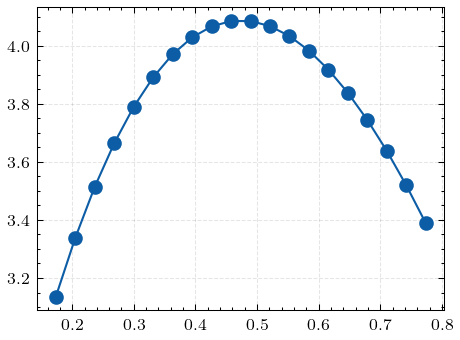

In [70]:
plt.plot(cs, p_plot)
plt.show()

In [73]:
h_1 = x_uns_1[1] - x_uns_1[0]
h_2 = x_uns_2[1] - x_uns_2[0]

momentum_uns_1 = p(u_c_k_uns_1(x_uns_1), h_1)
momentum_uns_2 = p(u_c_k_uns_2(x_uns_2), h_2)

p_p_c_k = (momentum_uns_2 - momentum_uns_1)/(c_uns_2 - c_uns_1)
p_p_c_k

3.163744997196666

# Comparison — $c = c^* \pm \epsilon$

In [167]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns = c_star - eps

In [168]:
############# Load stable DS ################
# Load theoretical soliton
### WORK IN PROGESS ###
#theo_st = pickle.load(open(path_st_three + "theo_st_c_0.77_k_-50.pck", "rb"))

#def w_dark_theo_st(x, t):
#    return theo_st(x - c_st * t)

# Load control stable
### WORK IN PROGESS ###
#files_control_st_three = load_files(folder_control_st_three_eps, 95_000)

# Load random perturbed stable
### WORK IN PROGESS ###
#files_random_st_three = load_files(folder_gauss_rand_st_three_eps, 95_000)

# Load constant perturbed stable
### NOT FINISHED ###
#files_cons_st_three = load_files(folder_gauss_st_three_eps, 89_500)

In [169]:
############# Load unstable DS ################
# Load theoretical soliton
theo_uns = pickle.load(open(path_uns_one + "theo_uns_c_0.37_k_-50.pck", "rb"))

def w_dark_theo_uns(x, t):
    return theo_uns(x - c_uns * t)

# Load control unstable
### WORK IN PROGESS ###
files_control_uns_one = load_files(folder_control_uns_one, 100_000)

# Load random perturbed unstable
### WORK IN PROGESS ###
files_ev_uns_one = load_files(folder_ev_uns_one, 100_000)

# Load constant perturbed unstable
files_cons_uns_one = load_files(folder_gauss_uns_one, 100_000)

In [170]:
### Files to plot ###

t = files_cons_uns_one["t"]
evec = files_ev_uns_one["evecs"]
eval = files_ev_uns_one["evals"]
eta_one = get_eta(N, eval, evec)
norm_ev = np.sqrt(h) * np_norm(1e-2*eta_one, ord=2)

#error_L2_st = files_control_st_three["error L2"]
#error_L2_g_rand_st = files_random_st_three["error L2"]
#error_L2_g_st = files_cons_st_three["error L2"]

#cond_0_st = error_L2_st!=0
#cond_0_rand_st = error_L2_g_rand_st!=0
#cond_0_cons_st = error_L2_g_st!=0

error_L2_uns = files_control_uns_one["error L2"]
error_L2_g_ev_uns = files_ev_uns_one["error L2"]
error_L2_g_uns = files_cons_uns_one["error L2"]

cond_0_uns = error_L2_uns!=0
cond_0_ev_uns = error_L2_g_ev_uns!=0
cond_0_cons_uns = error_L2_g_uns!=0

#t_cons_st = t[cond_0_cons_st]
#t_rand_st = t[cond_0_rand_st]

t_control_uns = t[cond_0_uns]
t_cons_uns = t[cond_0_cons_uns]
t_ev_uns = t[cond_0_ev_uns]

final_cond = t_control_uns<10#<0.1

tf_plot = 5 #0.005

### Stable ###
#plt.plot(t, error_L2_st, label="Control stable DS", marker="none")
#plt.plot(t_cons_st[t_cons_st<tf_plot], error_L2_g_st[cond_0_cons_st][t_cons_st<tf_plot]/norm_g_cons, label="Perturbed cons. stable DS", marker="none")
#plt.plot(t[cond_0_rand_st], error_L2_g_rand_st[cond_0_rand_st]/norm_g_rand, label="Perturbed rand. stable DS", marker="none")


Largest non-complex eigenvalue = (0.17859288162502915+0j)


In [171]:
#### Exponential fit ###
dt_control_one_uns = t_control_uns[1] - t_control_uns[0]
dt_cons_one_uns = t_cons_uns[1] - t_cons_uns[0]

Ti = 0.2
Tf = 2

t_cond_cons = np.logical_and(Ti<t_cons_uns, t_cons_uns<Tf)
t_cond_ev = np.logical_and(Ti<t_ev_uns, t_ev_uns<Tf)

def line_func(t, C, l):
    return l*t + C

pars_uns_cons, other = curve_fit(line_func, t_cons_uns[t_cond_cons], np.log(error_L2_g_uns[t_cond_cons]))
C_cons_uns, l_cons_uns = pars_uns_cons

pars_uns_ev, other = curve_fit(line_func, t_ev_uns[t_cond_ev], np.log(error_L2_g_ev_uns[t_cond_ev]))
C_ev_uns, l_ev_uns = pars_uns_ev

lambda_ev = np.real(eval[0])

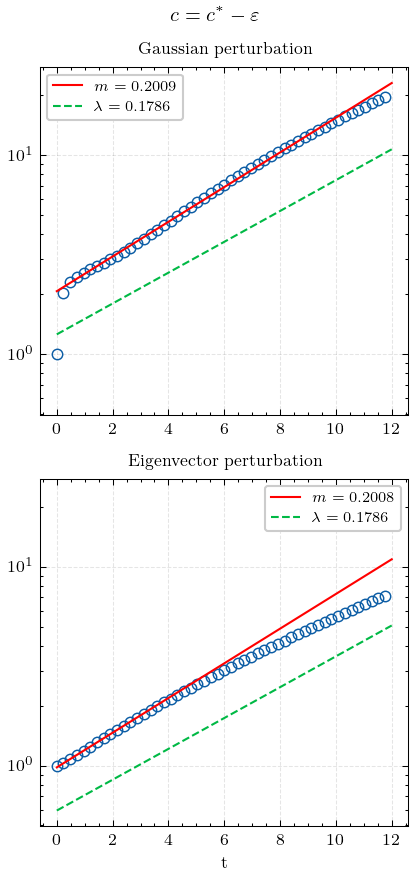

In [172]:
plot_unstable_subplots(
    "",
    t_cons=t_cons_uns,
    err_cons=error_L2_g_uns[cond_0_cons_uns],
    norm_cons=norm_g_cons,
    C_cons=C_cons_uns,
    m_cons=l_cons_uns,
    t_ev=t_ev_uns,
    err_ev=error_L2_g_ev_uns[cond_0_ev_uns],
    norm_ev=norm_ev,
    C_ev=C_ev_uns,
    m_ev=l_ev_uns,
    lambda_ev=np.real(eval[0]),
    line_func=line_func,
    ms=5,
    markeredgewidth=0.7,
    lw=1,
    path="Unstable/evs_comparison/one_eps.pdf"
)


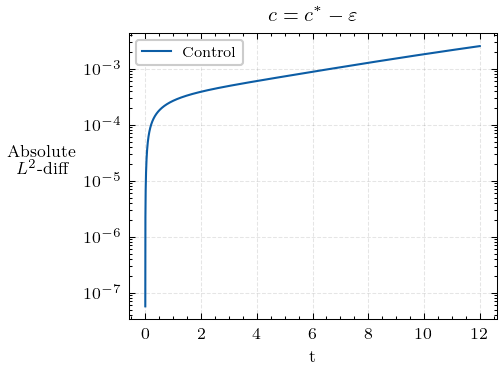

In [55]:
### Unstable: control ###
plt.plot(
    t_control_uns,
    error_L2_uns[cond_0_uns],
    ms=0,
    markerfacecolor='none',
    #markevery=1000,
    ls="-", label="Control")

plt.ylabel("Absolute \n" + r"$L^2$-diff", rotation='horizontal', ha='right', multialignment='center')
plt.xlabel("t")
plt.yscale("log")
plt.legend(fontsize=7)

plt.title(r"$c = c^*- \varepsilon$")
plt.tight_layout()
plt.show()


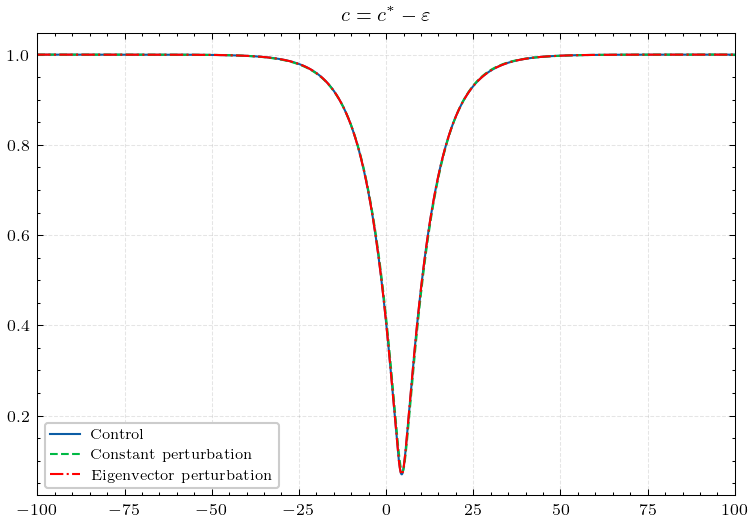

In [56]:
w_final_uns_control = files_control_uns_one["w final"]
w_final_uns_cons = files_cons_uns_one["w final"]
w_final_uns_ev = files_ev_uns_one["w final"]

plt.figure(figsize=(6, 4))
#plt.plot(x, norm(w_final_st), ls="-", marker="none", label="Control stable DS")
#plt.plot(x, norm(w_final_g_st), ls="--", marker="none", label="Perturbed cons. stable DS")]
plt.plot(x, norm(w_final_uns_control), ms=0, label="Control")
plt.plot(x, norm(w_final_uns_cons), ms=0, label="Constant perturbation")
plt.plot(x, norm(w_final_uns_ev), ms=0, label="Eigenvector perturbation", color="red")

plt.title(r"$c = c^*- \varepsilon$")
plt.legend(fontsize=7)
plt.xlim(-100, 100)

### Zoom border ###
#plt.xlim(L-2, L+.5)
#plt.ylim(1-1e-12, 1+1e-12)
plt.show()

# Comparison — $c = c^* \pm 2\epsilon$

In [173]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns = c_star - 2 * eps

In [174]:
############# Load stable DS ################
# Load theoretical soliton
### WORK IN PROGESS ###
#theo_st = pickle.load(open(path_st_two + "theo_st_c_0.77_k_-50.pck", "rb"))

#def w_dark_theo_st(x, t):
#    return theo_st(x - c_st * t)

# Load control stable
### WORK IN PROGESS ###
#files_control_st_three = load_files(folder_control_st_three_eps, 95_000)

# Load random perturbed stable
### WORK IN PROGESS ###
#files_random_st_three = load_files(folder_gauss_rand_st_three_eps, 95_000)

# Load constant perturbed stable
### NOT FINISHED ###
#files_cons_st_three = load_files(folder_gauss_st_three_eps, 89_500)

In [175]:
############# Load unstable DS ################
# Load theoretical soliton
theo_uns = pickle.load(open(path_uns_two + "theo_uns_c_0.27_k_-50.pck", "rb"))

def w_dark_theo_uns(x, t):
    return theo_uns(x - c_uns * t)

# Load control stable
### WORK IN PROGESS ###
files_control_uns_two = load_files(folder_control_uns_two, 100_000)

# Load random perturbed stable
### WORK IN PROGESS ###
files_ev_uns_two = load_files(folder_ev_uns_two, 100_000)

# Load constant perturbed stable
files_cons_uns_two = load_files(folder_gauss_uns_two, 100_000)

In [176]:
### Files to plot ###

t = files_cons_uns_two["t"]
evec = files_ev_uns_two["evecs"]
eval = files_ev_uns_two["evals"]
eta_two = get_eta(N, eval, evec)
norm_ev = np.sqrt(h) * np_norm(1e-2*eta_two, ord=2)

#error_L2_st = files_control_st_three["error L2"]
#error_L2_g_rand_st = files_random_st_three["error L2"]
#error_L2_g_st = files_cons_st_three["error L2"]

#cond_0_st = error_L2_st!=0
#cond_0_rand_st = error_L2_g_rand_st!=0
#cond_0_cons_st = error_L2_g_st!=0

error_L2_uns = files_control_uns_two["error L2"]
error_L2_g_ev_uns = files_ev_uns_two["error L2"]
error_L2_g_uns = files_cons_uns_two["error L2"]

cond_0_uns = error_L2_uns!=0
cond_0_ev_uns = error_L2_g_ev_uns!=0
cond_0_cons_uns = error_L2_g_uns!=0

#t_cons_st = t[cond_0_cons_st]
#t_rand_st = t[cond_0_rand_st]

t_control_uns = t[cond_0_uns]
t_cons_uns = t[cond_0_cons_uns]
t_ev_uns = t[cond_0_ev_uns]

final_cond = t_control_uns<10#<0.1

tf_plot = 5 #0.005

### Stable ###
#plt.plot(t, error_L2_st, label="Control stable DS", marker="none")
#plt.plot(t_cons_st[t_cons_st<tf_plot], error_L2_g_st[cond_0_cons_st][t_cons_st<tf_plot]/norm_g_cons, label="Perturbed cons. stable DS", marker="none")
#plt.plot(t[cond_0_rand_st], error_L2_g_rand_st[cond_0_rand_st]/norm_g_rand, label="Perturbed rand. stable DS", marker="none")


Largest non-complex eigenvalue = (0.4847178506215948+0j)


In [177]:
#### Exponential fit ###
dt_control_two_uns = t_control_uns[1] - t_control_uns[0]
dt_cons_two_uns = t_cons_uns[1] - t_cons_uns[0]

Ti = 0
Tf = 2

t_cond_cons = np.logical_and(Ti<t_cons_uns, t_cons_uns<Tf)
t_cond_ev = np.logical_and(Ti<t_ev_uns, t_ev_uns<Tf)

def line_func(t, C, l):
    return l*t + C

pars_uns_cons, other = curve_fit(line_func, t_cons_uns[t_cond_cons], np.log(error_L2_g_uns[t_cond_cons]))
C_cons_uns, l_cons_uns = pars_uns_cons

pars_uns_ev, other = curve_fit(line_func, t_ev_uns[t_cond_ev], np.log(error_L2_g_ev_uns[t_cond_ev]))
C_ev_uns, l_ev_uns = pars_uns_ev

lambda_ev = np.real(eval[0])

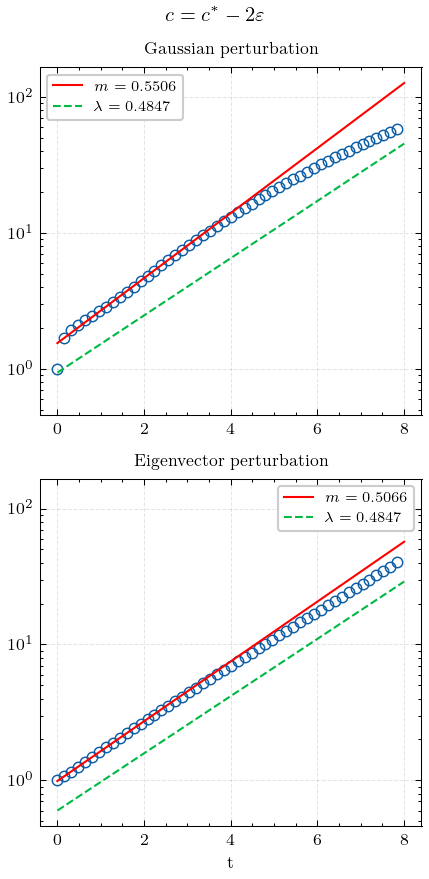

In [178]:
plot_unstable_subplots(n=2,
    t_cons=t_cons_uns,
    err_cons=error_L2_g_uns[cond_0_cons_uns],
    norm_cons=norm_g_cons,
    C_cons=C_cons_uns,
    m_cons=l_cons_uns,
    t_ev=t_ev_uns,
    err_ev=error_L2_g_ev_uns[cond_0_ev_uns],
    norm_ev=norm_ev,
    C_ev=C_ev_uns,
    m_ev=l_ev_uns,
    lambda_ev=np.real(eval[0]),
    line_func=line_func,
    ms=5,
    markeredgewidth=0.7,
    lw=1,
    path="Unstable/evs_comparison/two_eps.pdf"
)


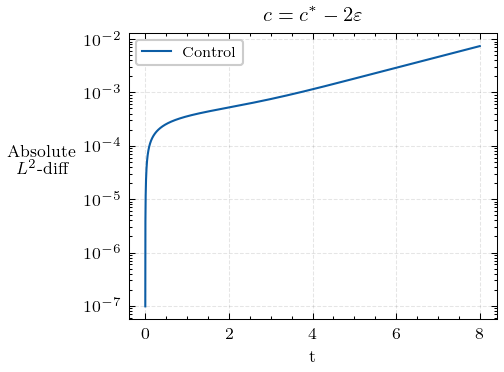

In [64]:
### Unstable: control ###
plt.plot(
    t_control_uns,
    error_L2_uns[cond_0_uns],
    ms=0,
    markerfacecolor='none',
    #markevery=1000,
    ls="-", label="Control")

plt.ylabel("Absolute \n" + r"$L^2$-diff", rotation='horizontal', ha='right', multialignment='center')
plt.xlabel("t")
plt.yscale("log")
plt.legend(fontsize=7)

plt.title(r"$c = c^*- 2\varepsilon$")
plt.tight_layout()
plt.show()


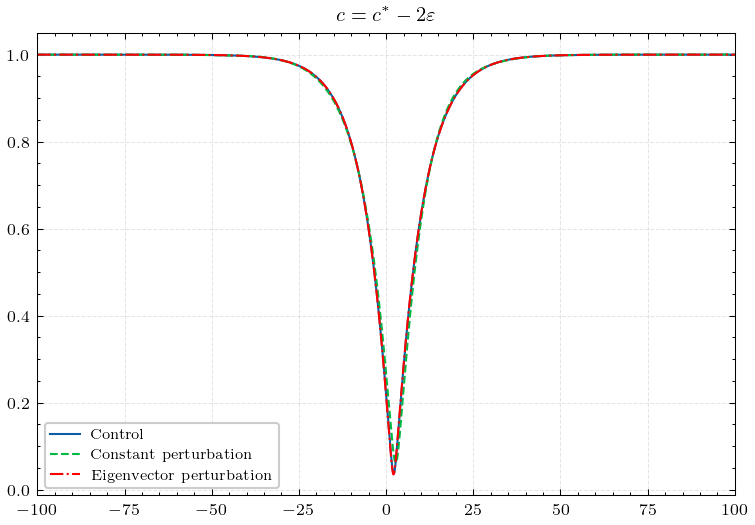

In [65]:
w_final_uns_control = files_control_uns_two["w final"]
w_final_uns_cons = files_cons_uns_two["w final"]
w_final_uns_ev = files_ev_uns_two["w final"]

plt.figure(figsize=(6, 4))
#plt.plot(x, norm(w_final_st), ls="-", marker="none", label="Control stable DS")
#plt.plot(x, norm(w_final_g_st), ls="--", marker="none", label="Perturbed cons. stable DS")]
plt.plot(x, norm(w_final_uns_control), ms=0, label="Control")
plt.plot(x, norm(w_final_uns_cons), ms=0, label="Constant perturbation")
plt.plot(x, norm(w_final_uns_ev), ms=0, label="Eigenvector perturbation", color="red")

plt.title(r"$c = c^*- 2\varepsilon$")
plt.legend(fontsize=7)
plt.xlim(-100, 100)

### Zoom border ###
#plt.xlim(L-2, L+.5)
#plt.ylim(1-1e-12, 1+1e-12)
plt.show()

# Comparison — $c = c^* \pm 3\epsilon$

In [7]:
k = -50
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c_uns = c_star - 3 * eps

In [8]:
############# Load stable DS ################
# Load theoretical soliton
### WORK IN PROGESS ###
theo_st = pickle.load(open(path_st_three + "theo_st_c_0.77_k_-50.pck", "rb"))

def w_dark_theo_st(x, t):
    return theo_st(x - c_st * t)

# Load control stable
### WORK IN PROGESS ###
#files_control_st_three = load_files(folder_control_st_three_eps, 95_000)

# Load random perturbed stable
### WORK IN PROGESS ###
#files_random_st_three = load_files(folder_gauss_rand_st_three_eps, 95_000)

# Load constant perturbed stable
### NOT FINISHED ###
#files_cons_st_three = load_files(folder_gauss_st_three_eps, 89_500)

In [9]:
############# Load unstable DS ################
# Load theoretical soliton
theo_uns = pickle.load(open(path_uns_three + "theo_uns_c_0.17_k_-50.pck", "rb"))

def w_dark_theo_uns(x, t):
    return theo_uns(x - c_uns * t)

# Load control stable
### WORK IN PROGESS ###
files_control_uns_three = load_files(folder_control_uns_three, 100_000)

# Load random perturbed stable
### WORK IN PROGESS ###
files_ev_uns_three = load_files(folder_ev_uns_three, 100_000)

# Load constant perturbed stable
files_cons_uns_three = load_files(folder_gauss_uns_three, 100_000)

In [10]:
### Files to plot ###

t = files_cons_uns_three["t"]
evec = files_ev_uns_three["evecs"]
eval = files_ev_uns_three["evals"]
eta_three = get_eta(N, eval, evec)
norm_ev = np.sqrt(h) * np_norm(1e-2*eta_three, ord=2)

#error_L2_st = files_control_st_three["error L2"]
#error_L2_g_rand_st = files_random_st_three["error L2"]
#error_L2_g_st = files_cons_st_three["error L2"]

#cond_0_st = error_L2_st!=0
#cond_0_rand_st = error_L2_g_rand_st!=0
#cond_0_cons_st = error_L2_g_st!=0

error_L2_uns = files_control_uns_three["error L2"]
error_L2_g_ev_uns = files_ev_uns_three["error L2"]
error_L2_g_uns = files_cons_uns_three["error L2"]

cond_0_uns = error_L2_uns!=0
cond_0_ev_uns = error_L2_g_ev_uns!=0
cond_0_cons_uns = error_L2_g_uns!=0

#t_cons_st = t[cond_0_cons_st]
#t_rand_st = t[cond_0_rand_st]

t_control_uns = t[cond_0_uns]
t_cons_uns = t[cond_0_cons_uns]
t_ev_uns = t[cond_0_ev_uns]

final_cond = t_control_uns<10#<0.1

tf_plot = 5 #0.005

### Stable ###
#plt.plot(t, error_L2_st, label="Control stable DS", marker="none")
#plt.plot(t_cons_st[t_cons_st<tf_plot], error_L2_g_st[cond_0_cons_st][t_cons_st<tf_plot]/norm_g_cons, label="Perturbed cons. stable DS", marker="none")
#plt.plot(t[cond_0_rand_st], error_L2_g_rand_st[cond_0_rand_st]/norm_g_rand, label="Perturbed rand. stable DS", marker="none")


Largest non-complex eigenvalue = (1.5302127855960503+0j)


In [11]:
#### Exponential fit ###
dt_control_three_uns = t_control_uns[1] - t_control_uns[0]
dt_cons_three_uns = t_cons_uns[1] - t_cons_uns[0]

Ti = 0
Tf = 2

t_cond_cons = np.logical_and(Ti<t_cons_uns, t_cons_uns<Tf)
t_cond_ev = np.logical_and(Ti<t_ev_uns, t_ev_uns<Tf)

def line_func(t, C, l):
    return l*t + C

pars_uns_cons, other = curve_fit(line_func, t_cons_uns[t_cond_cons], np.log(error_L2_g_uns[t_cond_cons]))
C_cons_uns, l_cons_uns = pars_uns_cons

pars_uns_ev, other = curve_fit(line_func, t_ev_uns[t_cond_ev], np.log(error_L2_g_ev_uns[t_cond_ev]))
C_ev_uns, l_ev_uns = pars_uns_ev

lambda_ev = np.real(eval[0])

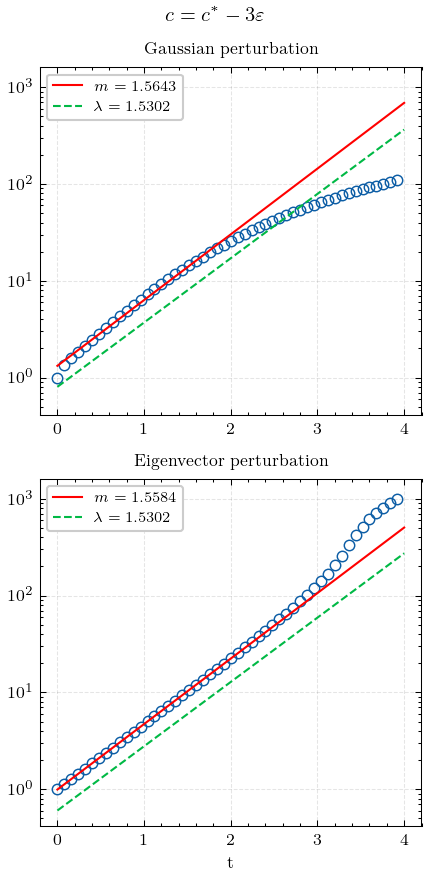

In [12]:
plot_unstable_subplots(
    n=3,
    t_cons=t_cons_uns,
    err_cons=error_L2_g_uns[cond_0_cons_uns],
    norm_cons=norm_g_cons,
    C_cons=C_cons_uns,
    m_cons=l_cons_uns,
    t_ev=t_ev_uns,
    err_ev=error_L2_g_ev_uns[cond_0_ev_uns],
    norm_ev=norm_ev,
    C_ev=C_ev_uns,
    m_ev=l_ev_uns,
    lambda_ev=np.real(eval[0]),
    line_func=line_func,
    ms=5,
    markeredgewidth=0.7,
    lw=1,
    path="Unstable/evs_comparison/three_eps.pdf"
)


Away from linear stability (left)

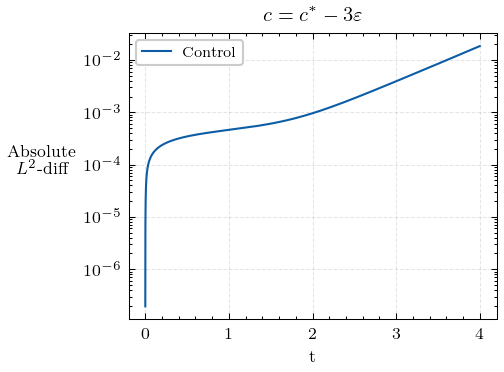

In [151]:
### Unstable: control ###
plt.plot(
    t_control_uns,
    error_L2_uns[cond_0_uns],
    ms=0,
    markerfacecolor='none',
    #markevery=1000,
    ls="-", label="Control")

plt.ylabel("Absolute \n" + r"$L^2$-diff", rotation='horizontal', ha='right', multialignment='center')
plt.xlabel("t")
plt.yscale("log")
plt.legend(fontsize=7)

plt.title(r"$c = c^*- 3\varepsilon$")
plt.tight_layout()
plt.show()


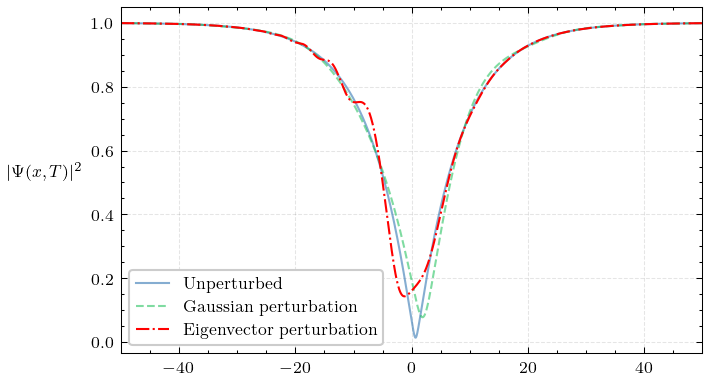

In [13]:
w_final_uns_control = files_control_uns_three["w final"]
w_final_uns_cons = files_cons_uns_three["w final"]
w_final_uns_ev = files_ev_uns_three["w final"]

plt.figure(figsize=(5, 3))
#plt.plot(x, norm(w_final_st), ls="-", marker="none", label="Control stable DS")
#plt.plot(x, norm(w_final_g_st), ls="--", marker="none", label="Perturbed cons. stable DS")]
plt.plot(x, norm(w_final_uns_control), ms=0, label="Unperturbed", alpha=0.5)
plt.plot(x, norm(w_final_uns_cons), ms=0, label="Gaussian perturbation", alpha=0.5)
plt.plot(x, norm(w_final_uns_ev), ms=0, label="Eigenvector perturbation", color="red")

plt.ylabel(r"$|\Psi(x, T)|^2$", rotation='horizontal', ha='right', multialignment='center')

plt.legend(fontsize=8)
plt.xlim(-50, 50)

### Zoom border ###
#plt.xlim(L-2, L+.5)
#plt.ylim(1-1e-12, 1+1e-12)

plt.savefig("Unstable/evs_comparison/final_time_sol.pdf", dpi=300, bbox_inches='tight')
plt.show()

End here

## Eigenvectors

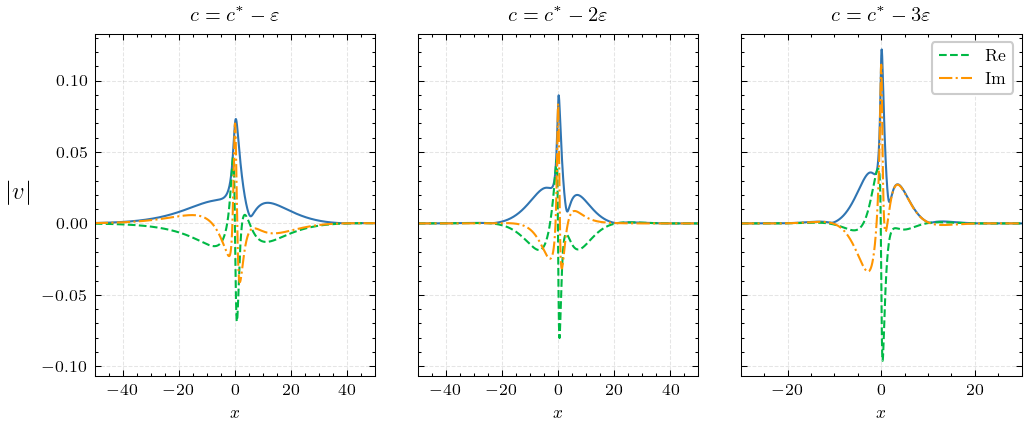

In [114]:
fig, axs = plt.subplots(1, 3, figsize=(7, 3), sharey=True)
axs[0].plot(x, np.abs(eta_one), ms=0, alpha=0.85)
axs[0].plot(x, np.real(eta_one), ms=0)
axs[0].plot(x, np.imag(eta_one), ms=0)

axs[1].plot(x, np.abs(eta_two), ms=0, alpha=0.85)
axs[1].plot(x, np.real(eta_two), ms=0)
axs[1].plot(x, np.imag(eta_two), ms=0)

axs[2].plot(x, np.abs(eta_three), ms=0, alpha=0.85)
axs[2].plot(x, np.real(eta_three), ms=0, label=r"Re")
axs[2].plot(x, np.imag(eta_three), ms=0, label=r"Im")

axs[0].set_xlim(-50, 50)
axs[1].set_xlim(-50, 50)
axs[2].set_xlim(-30, 30)
axs[0].set_ylabel(r"$|v|$", rotation='horizontal', ha='right', fontsize=12)

axs[0].set_xlabel(r"$x$")
axs[1].set_xlabel(r"$x$")
axs[2].set_xlabel(r"$x$")

axs[2].legend()

axs[0].set_title(r"$c = c^*-\varepsilon$")
axs[1].set_title(r"$c = c^*-2\varepsilon$")
axs[2].set_title(r"$c = c^*-3\varepsilon$")

plt.tight_layout()
#plt.suptitle("Eigenvector associated to the largest non-complex eigenvalue", y=1.02, fontsize=12)
plt.savefig("Unstable/evs_comparison/evecs.pdf", dpi=300, bbox_inches='tight')
plt.show()

# Plot $c = c^* - \varepsilon$

In [34]:
L = 10_000
N = 1_000_000
Nt = 100_000

x = np.linspace(-L, L, N)
Nelem = 200

N_times = Nt/Nelem

N_elem_final = int(Nt/N_times)
w_sim = np.zeros((N_elem_final+1, N), dtype="complex")#, fill_value=None)


for n in range(0, Nt+1, int(N_times)):
    j = int(n/N_times)

    sol_file = gzip.GzipFile(folder_control_uns_one+"w_" + f"{n:010d}" +".npy.gz", "r")
    sol_n = np.load(sol_file)
    w_sim[j] = sol_n.flatten().tolist()

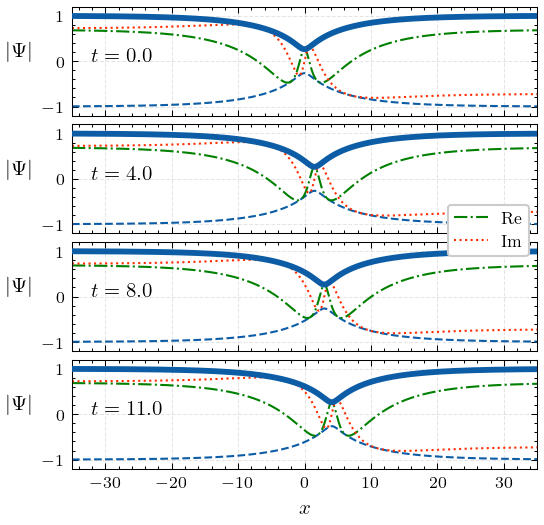

In [55]:
times_to_plot = [0, 4, 8, 11]

plot_snapshots(x, t[::int(N_times)], w_sim[:-1], times_to_plot, figsize=(4, 4), L=35, text_pos=(0.04, 0.50), save_path="DS_D2_unstable.pdf")